In [34]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy
from scipy.stats import ttest_ind

print("All libraries imported successfully!")

All libraries imported successfully!


In [35]:
chicks = pd.read_csv("chickwts.csv")

print(chicks.head())

feed_means = chicks.groupby("feed")["weight"].mean().sort_values()

print("\nAverage Weight by Feed:")
print(feed_means)

   Unnamed: 0  weight       feed
0           1     179  horsebean
1           2     160  horsebean
2           3     136  horsebean
3           4     227  horsebean
4           5     217  horsebean

Average Weight by Feed:
feed
horsebean    160.200000
linseed      218.750000
soybean      246.428571
meatmeal     276.909091
casein       323.583333
sunflower    328.916667
Name: weight, dtype: float64


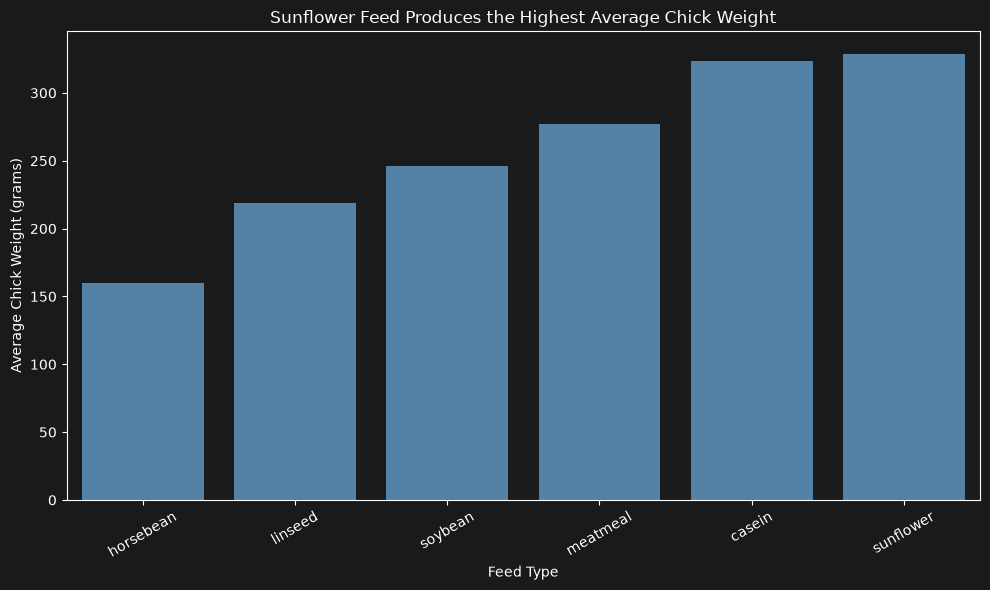

In [36]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=feed_means.index,
    y=feed_means.values,
    color="steelblue"
)

plt.title("Sunflower Feed Produces the Highest Average Chick Weight")
plt.xlabel("Feed Type")
plt.ylabel("Average Chick Weight (grams)")
plt.xticks(rotation=30)
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()

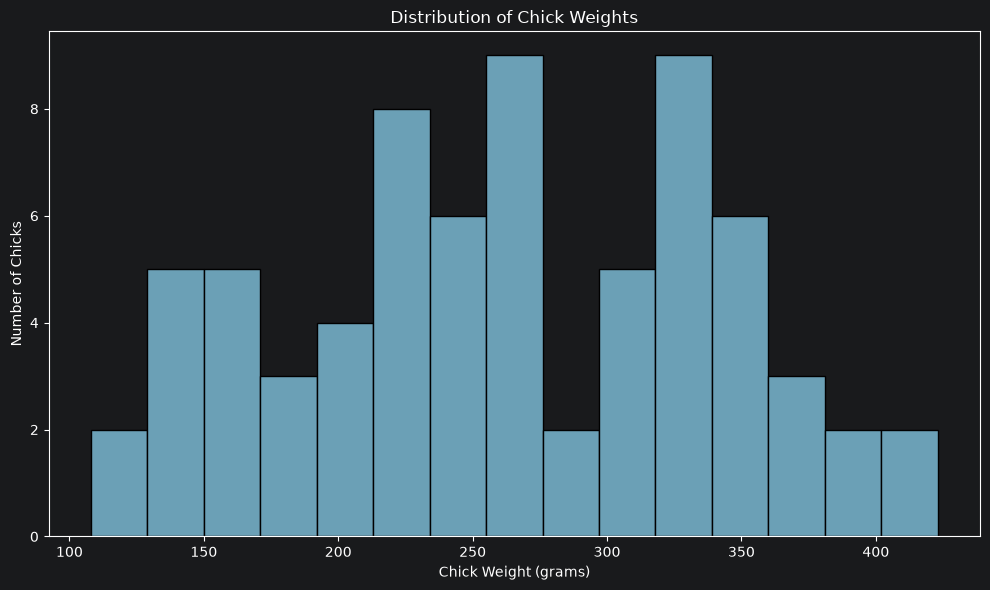

In [37]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=chicks,
    x="weight",
    bins=15,
    color="skyblue"
)

plt.title("Distribution of Chick Weights")
plt.xlabel("Chick Weight (grams)")
plt.ylabel("Number of Chicks")
plt.tight_layout()
plt.show()

In [38]:
museum = pd.read_csv("museum_visitors.csv")

print(museum.head())
print(museum.columns.tolist())

         Date  Avila Adobe  Firehouse Museum  Chinese American Museum  \
0  2014-01-01        24778              4486                     1581   
1  2014-02-01        18976              4172                     1785   
2  2014-03-01        25231              7082                     3229   
3  2014-04-01        26989              6756                     2129   
4  2014-05-01        36883             10858                     3676   

   America Tropical Interpretive Center  
0                                  6602  
1                                  5029  
2                                  8129  
3                                  2824  
4                                 10694  
['Date', 'Avila Adobe', 'Firehouse Museum', 'Chinese American Museum', 'America Tropical Interpretive Center']


In [39]:
sales = pd.read_csv("sales_clean.csv")

print(sales.columns.tolist())
print(sales.dtypes)
print(sales.head())

['order_id', 'date', 'product', 'price', 'qty', 'zip']
order_id      int64
date            str
product         str
price       float64
qty           int64
zip           int64
dtype: object
   order_id        date   product  price  qty    zip
0      1254  2026-04-06       mug  11.36    4  60614
1      1057  2026-05-30   charger  14.79    3  30303
2      1150  2026-05-06       mug   5.50    1  10001
3      1066  2026-05-30  notebook  37.53    1  98101
4      1114  2026-04-06    webcam  45.59    4  90405


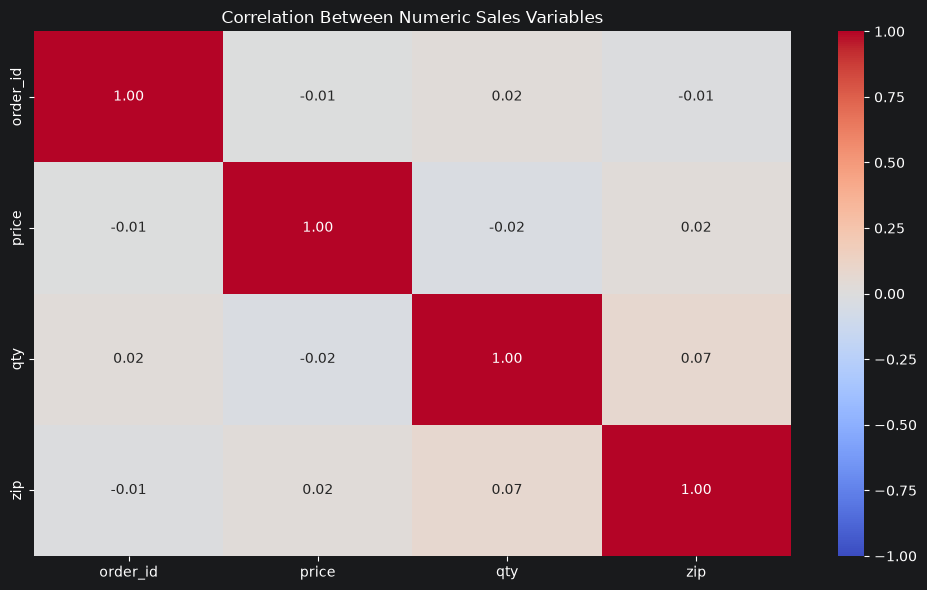

In [40]:
numeric_sales = sales.select_dtypes(include="number")

correlation = numeric_sales.corr()

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numeric Sales Variables")
plt.tight_layout()
plt.show()

In [41]:
# Heatmap Analysis
# I created a heatmap using my cleaned sales data to understand the relationships between numerical variables. The heatmap uses colors to show how strongly the variables are related.

In [42]:
sunflower = chicks[chicks["feed"] == "sunflower"]["weight"]
horsebean = chicks[chicks["feed"] == "horsebean"]["weight"]

print("Sunflower sample size:", len(sunflower))
print("Horsebean sample size:", len(horsebean))

sunflower_mean = sunflower.mean()
horsebean_mean = horsebean.mean()

difference = sunflower_mean - horsebean_mean

t_stat, p_value = ttest_ind(
    sunflower,
    horsebean,
    equal_var=False
)

print(f"Sunflower mean: {sunflower_mean:.2f} grams")
print(f"Horsebean mean: {horsebean_mean:.2f} grams")
print(f"Difference: {difference:.2f} grams")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.8g}")

Sunflower sample size: 12
Horsebean sample size: 10
Sunflower mean: 328.92 grams
Horsebean mean: 160.20 grams
Difference: 168.72 grams
T-statistic: 9.0449
P-value: 1.6903886e-08


In [43]:
# Null Hypothesis
# My null hypothesis is there is no difference in the average weight of chicks fed sunflower feed compared to chicks fed horsebean feed.

# Alternative hypothesis is there is a difference in average weight between the two groups.

# A independent two sample t-test.
# Determines whether the difference is at the 0.05 significant level.

In [44]:
# Conclusion
# Based on these results, I would reject the null hypothesis because there is a statistically significant difference in average chick weight between the two feed groups.